In [2]:
import numpy as np 
import matplotlib.pyplot as plt

In [5]:
space = np.linspace(-10, 10, 21)

In [7]:
X, Y = np.meshgrid(space, space)

In [12]:
X[0][1]

np.float64(-9.0)

In [13]:
Y[0][1]

np.float64(-10.0)

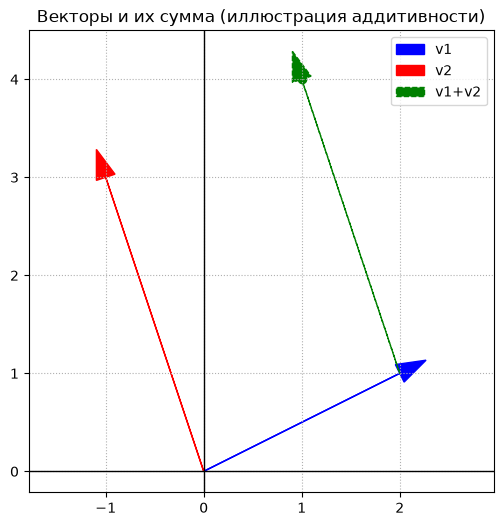

In [14]:
# Векторы
v1 = np.array([2, 1])
v2 = np.array([-1, 3])

plt.figure(figsize=(6, 6))
# Рисуем оси
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)

# Рисуем векторы как стрелки из (0,0)
plt.arrow(0, 0, v1[0], v1[1], head_width=0.2, head_length=0.3, fc='blue', ec='blue', label='v1')
plt.arrow(0, 0, v2[0], v2[1], head_width=0.2, head_length=0.3, fc='red', ec='red', label='v2')

# Добавим сумму векторов (иллюстрация линейности: v1 + v2)
v_sum = v1 + v2
plt.arrow(v1[0], v1[1], v_sum[0] - v1[0], v_sum[1] - v1[1],
          head_width=0.2, head_length=0.3, fc='green', ec='green', linestyle='--', label='v1+v2')
plt.scatter(v_sum[0], v_sum[1], color='green')

plt.xlim(-3, 4)
plt.ylim(-2, 5)
plt.grid(True, linestyle=':')
plt.legend()
plt.axis('equal')  # важно: чтобы квадраты были квадратами, а не прямоугольниками
plt.title('Векторы и их сумма (иллюстрация аддитивности)')
plt.show()


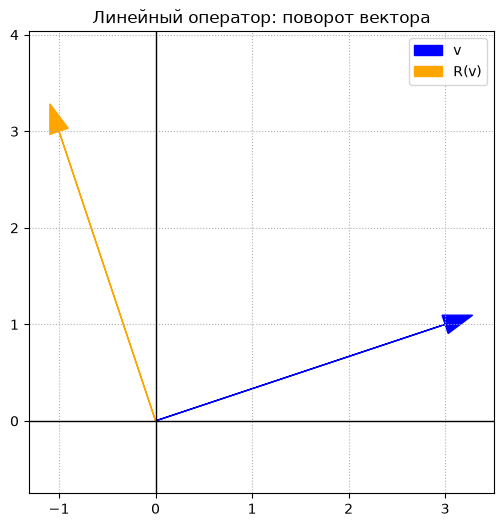

In [18]:
theta = np.pi / 2
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta), np.cos(theta)]])

v = np.array([3, 1])
Rv = R @ v  # применение оператора (умножение матрицы на вектор)

plt.figure(figsize=(6, 6))
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)

plt.arrow(0, 0, v[0], v[1], head_width=0.2, head_length=0.3, fc='blue', ec='blue', label='v')
plt.arrow(0, 0, Rv[0], Rv[1], head_width=0.2, head_length=0.3, fc='orange', ec='orange', label='R(v)')

plt.xlim(-4, 4)
plt.ylim(-4, 4)
plt.grid(True, linestyle=':')
plt.legend()
plt.axis('equal')
plt.title('Линейный оператор: поворот вектора')
plt.show()


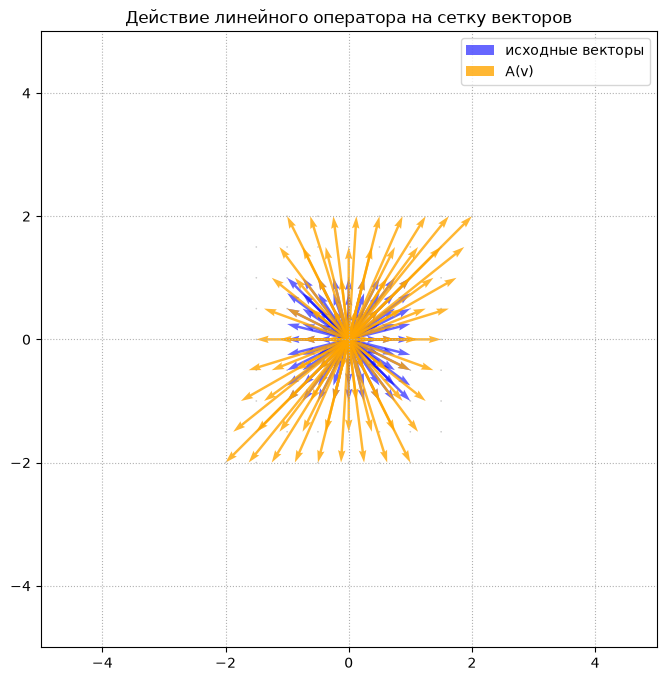

In [19]:
# Сетка точек
x = np.linspace(-2, 2, 9)
y = np.linspace(-2, 2, 9)
X, Y = np.meshgrid(x, y)

# Превращаем в список векторов
points = np.column_stack([X.ravel(), Y.ravel()])

# Применяем оператор (растяжение по x и сдвиг по y — но без свободного члена!)
A = np.array([[1.5, 0.5],
              [0.0, 2.0]])

points_transformed = (A @ points.T).T

plt.figure(figsize=(8, 8))
ax = plt.gca()

# Исходная сетка
ax.quiver(points[:, 0], points[:, 1],
          np.zeros_like(points[:, 0]), np.zeros_like(points[:, 1]),
          color='gray', scale=1, width=0.003, alpha=0.4)  # просто точки
# Стрелки исходной сетки
ax.quiver(np.zeros_like(points[:, 0]), np.zeros_like(points[:, 1]),
          points[:, 0], points[:, 1],
          color='blue', scale=20, width=0.004, alpha=0.6, label='исходные векторы')

# Трансформированные векторы
ax.quiver(np.zeros_like(points_transformed[:, 0]),
          np.zeros_like(points_transformed[:, 1]),
          points_transformed[:, 0], points_transformed[:, 1],
          color='orange', scale=20, width=0.004, alpha=0.8, label='A(v)')

ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)
ax.grid(True, linestyle=':')
ax.legend()
ax.set_aspect('equal')
ax.set_title('Действие линейного оператора на сетку векторов')
plt.show()


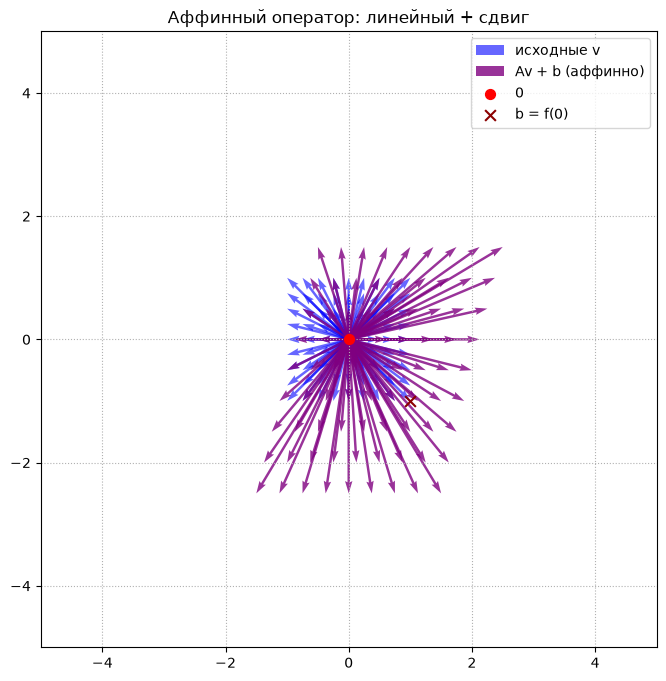

In [20]:
b = np.array([1, -1])  # сдвиг
affine_points = (A @ points.T).T + b

plt.figure(figsize=(8, 8))
ax = plt.gca()

ax.quiver(np.zeros_like(points[:, 0]), np.zeros_like(points[:, 1]),
          points[:, 0], points[:, 1],
          color='blue', scale=20, width=0.004, alpha=0.6, label='исходные v')

ax.quiver(np.zeros_like(affine_points[:, 0]),
          np.zeros_like(affine_points[:, 1]),
          affine_points[:, 0], affine_points[:, 1],
          color='purple', scale=20, width=0.004, alpha=0.8, label='Av + b (аффинно)')

# Покажем, что начало координат ушло
ax.scatter(0, 0, color='red', s=50, zorder=5, label='0')
ax.scatter(b[0], b[1], color='darkred', s=60, marker='x', zorder=5, label='b = f(0)')

ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)
ax.grid(True, linestyle=':')
ax.legend()
ax.set_aspect('equal')
ax.set_title('Аффинный оператор: линейный + сдвиг')
plt.show()


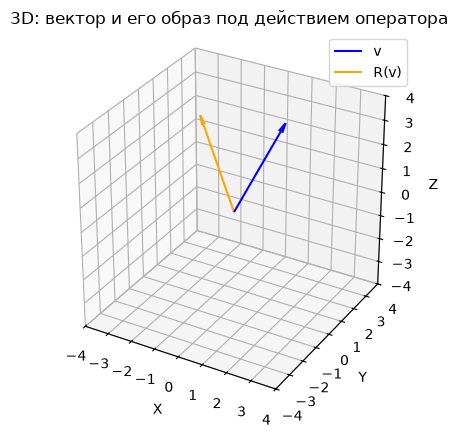

In [21]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

v = np.array([1, 2, 3])
A = np.array([[0, -1, 0],
              [1,  0, 0],
              [0,  0, 1]])  # поворот вокруг оси Z на 90°
Rv = A @ v

ax.quiver(0, 0, 0, v[0], v[1], v[2], color='blue', arrow_length_ratio=0.1, label='v')
ax.quiver(0, 0, 0, Rv[0], Rv[1], Rv[2], color='orange', arrow_length_ratio=0.1, label='R(v)')

ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_zlim(-4, 4)
ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
ax.legend()
ax.set_box_aspect([1,1,1])
plt.title('3D: вектор и его образ под действием оператора')
plt.show()


IndexError: invalid index to scalar variable.

/Users/mac/university/.venv/lib/python3.13/site-packages/matplotlib/transforms.py:1913: ComplexWarning: Casting complex values to real discards the imaginary part
  return affine_transform(values, mtx)
/Users/mac/university/.venv/lib/python3.13/site-packages/matplotlib/text.py:863: ComplexWarning: Casting complex values to real discards the imaginary part
  posx = float(self.convert_xunits(x))
/Users/mac/university/.venv/lib/python3.13/site-packages/matplotlib/text.py:864: ComplexWarning: Casting complex values to real discards the imaginary part
  posy = float(self.convert_yunits(y))
/Users/mac/university/.venv/lib/python3.13/site-packages/matplotlib/text.py:1012: ComplexWarning: Casting complex values to real discards the imaginary part
  x = float(self.convert_xunits(self._x))
/Users/mac/university/.venv/lib/python3.13/site-packages/matplotlib/text.py:1013: ComplexWarning: Casting complex values to real discards the imaginary part
  y = float(self.convert_yunits(self._y))




In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Матрица с известными собственными значениями
A = np.array([[2, 0],
              [0, 0.5]])

# Собственные значения и векторы
eigvals, eigvecs = np.linalg.eig(A)

# eigvecs[:, i] — i-й собственный вектор (столбец)
v1 = eigvecs[:, 0]
v2 = eigvecs[:, 1]
lambda1 = eigvals[0]
lambda2 = eigvals[1]

# Нормализуем для рисования (чтобы стрелки были удобной длины)
def normalize(v):
    return v / np.linalg.norm(v)

v1_n = normalize(v1)
v2_n = normalize(v2)

# Векторы после действия оператора
Av1 = A @ v1_n
Av2 = A @ v2_n

plt.figure(figsize=(8, 8))
ax = plt.gca()

# Оси
ax.axhline(0, color='black', linewidth=1)
ax.axvline(0, color='black', linewidth=1)

# Исходные собственные векторы (синие)
ax.quiver(0, 0, v1_n[0], v1_n[1], angles='xy', scale_units='xy', scale=1,
          color='blue', width=0.006, label=f'v1, λ={lambda1:.2f}')
ax.quiver(0, 0, v2_n[0], v2_n[1], angles='xy', scale_units='xy', scale=1,
          color='darkblue', width=0.006, label=f'v2, λ={lambda2:.2f}')

# Образы векторов после действия матрицы (оранжевые)
ax.quiver(0, 0, Av1[0], Av1[1], angles='xy', scale_units='xy', scale=1,
          color='orange', width=0.006, linestyle='--', label='A(v)')
ax.quiver(0, 0, Av2[0], Av2[1], angles='xy', scale_units='xy', scale=1,
          color='darkorange', width=0.006, linestyle='--')

# Подписи собственных значений рядом с концами стрелок
ax.text(Av1[0]*1.1, Av1[1]*1.1, f'λ={lambda1:.2f}', color='orange', fontsize=12)
ax.text(Av2[0]*1.1, Av2[1][1]*1.1, f'λ={lambda2:.2f}', color='darkorange', fontsize=12)

ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-2.5, 2.5)
ax.grid(True, linestyle=':')
ax.legend(loc='upper left')
ax.set_aspect('equal')
ax.set_title('Собственные векторы и собственные значения: растяжение вдоль направлений')
plt.show()


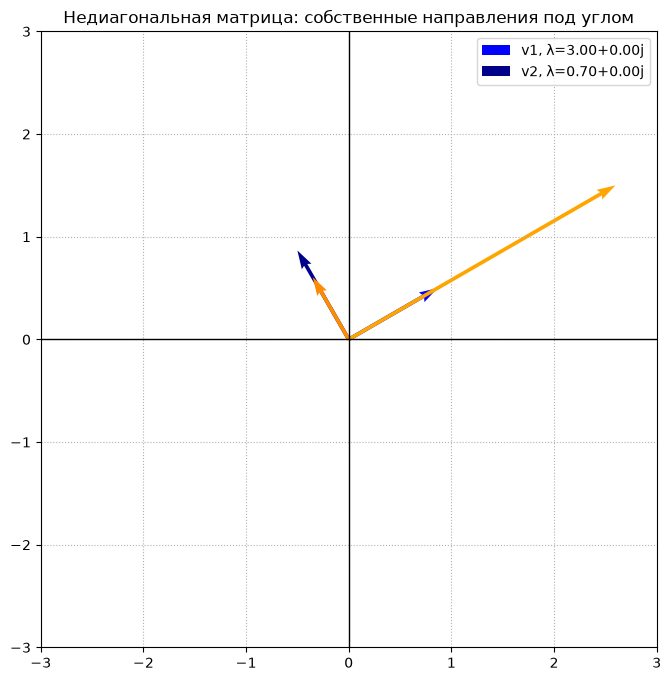

In [23]:
theta = np.pi / 6  # 30 градусов
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])

S = np.array([[3, 0],
              [0, 0.7]])  # растяжение

A = R @ S @ R.T  # симметричная матрица: поворот, растяжение, обратно

eigvals, eigvecs = np.linalg.eig(A)
v1 = normalize(eigvecs[:, 0])
v2 = normalize(eigvecs[:, 1])
Av1 = A @ v1
Av2 = A @ v2

plt.figure(figsize=(8, 8))
ax = plt.gca()
ax.axhline(0, color='black', linewidth=1)
ax.axvline(0, color='black', linewidth=1)

ax.quiver(0, 0, v1[0], v1[1], angles='xy', scale_units='xy', scale=1,
          color='blue', width=0.006, label=f'v1, λ={eigvals[0]:.2f}')
ax.quiver(0, 0, v2[0], v2[1], angles='xy', scale_units='xy', scale=1,
          color='darkblue', width=0.006, label=f'v2, λ={eigvals[1]:.2f}')

ax.quiver(0, 0, Av1[0], Av1[1], angles='xy', scale_units='xy', scale=1,
          color='orange', width=0.006, linestyle='--')
ax.quiver(0, 0, Av2[0], Av2[1], angles='xy', scale_units='xy', scale=1,
          color='darkorange', width=0.006, linestyle='--')

ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.grid(True, linestyle=':')
ax.legend()
ax.set_aspect('equal')
ax.set_title('Недиагональная матрица: собственные направления под углом')
plt.show()


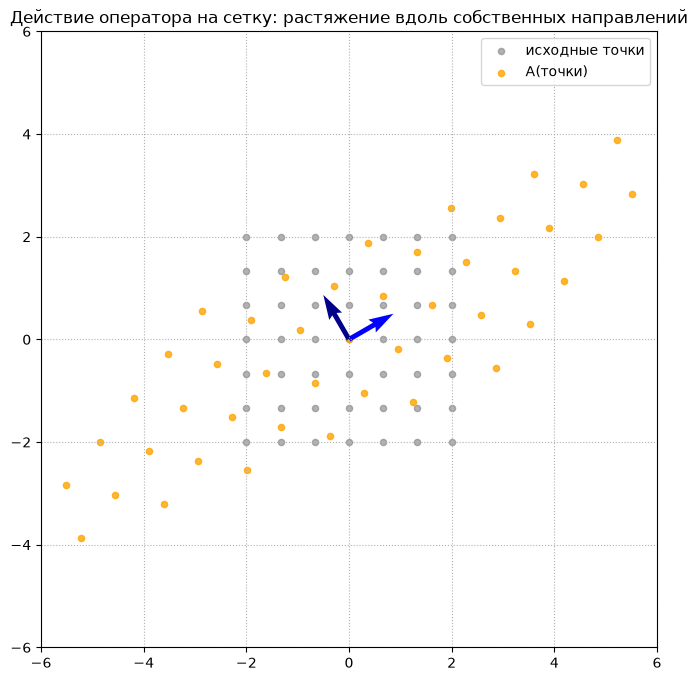

In [25]:
x = np.linspace(-2, 2, 7)
y = np.linspace(-2, 2, 7)
X, Y = np.meshgrid(x, y)
points = np.column_stack([X.ravel(), Y.ravel()])

points_transformed = (A @ points.T).T

plt.figure(figsize=(8, 8))
ax = plt.gca()

# Сетка до
ax.scatter(points[:, 0], points[:, 1], color='gray', s=20, alpha=0.6, label='исходные точки')
# Сетка после
ax.scatter(points_transformed[:, 0], points_transformed[:, 1], color='orange', s=20, alpha=0.8, label='A(точки)')

# Собственные векторы
ax.quiver(0, 0, v1[0], v1[1], angles='xy', scale_units='xy', scale=1, color='blue', width=0.008)
ax.quiver(0, 0, v2[0], v2[1], angles='xy', scale_units='xy', scale=1, color='darkblue', width=0.008)

ax.set_xlim(-6, 6)
ax.set_ylim(-6, 6)
ax.grid(True, linestyle=':')
ax.legend()
ax.set_aspect('equal')
ax.set_title('Действие оператора на сетку: растяжение вдоль собственных направлений')
plt.show()


Собственные значения (комплексные): [0.70710678+0.70710678j 0.70710678-0.70710678j]


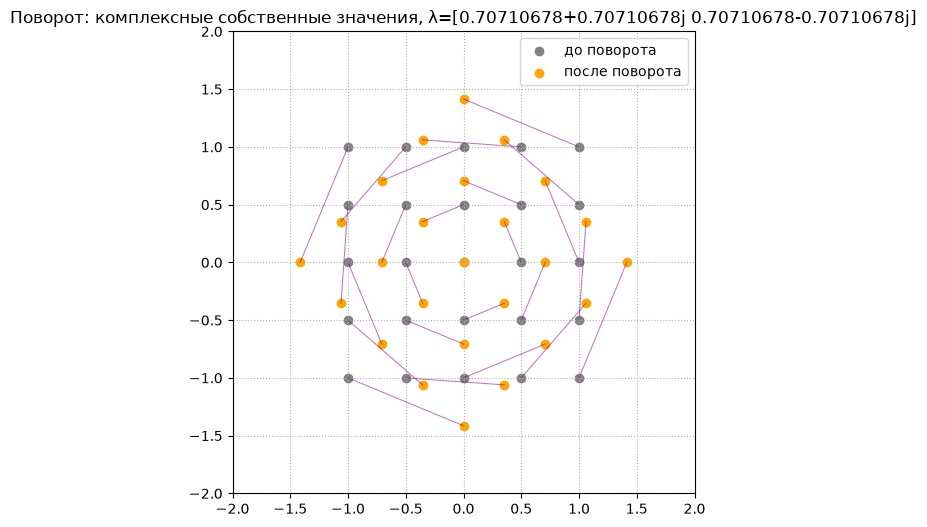

In [26]:
theta = np.pi / 4
A_rot = np.array([[np.cos(theta), -np.sin(theta)],
                  [np.sin(theta),  np.cos(theta)]])

eigvals, _ = np.linalg.eig(A_rot)
print("Собственные значения (комплексные):", eigvals)

x = np.linspace(-1, 1, 5)
y = np.linspace(-1, 1, 5)
X, Y = np.meshgrid(x, y)
points = np.column_stack([X.ravel(), Y.ravel()])
points_rot = (A_rot @ points.T).T

plt.figure(figsize=(6, 6))
ax = plt.gca()
ax.scatter(points[:, 0], points[:, 1], color='gray', label='до поворота')
ax.scatter(points_rot[:, 0], points_rot[:, 1], color='orange', label='после поворота')

for i in range(len(points)):
    ax.plot([points[i, 0], points_rot[i, 0]],
            [points[i, 1], points_rot[i, 1]],
            color='purple', linewidth=0.8, alpha=0.5)

ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.grid(True, linestyle=':')
ax.legend()
ax.set_aspect('equal')
ax.set_title(f'Поворот: комплексные собственные значения, λ={eigvals}')
plt.show()
